# Test 01 — Boris 粒子推进

图中显示粒子在均匀磁场中的 x-y 轨迹，以及速度大小是否保持不变。下面也检查电场加速和周期边界。

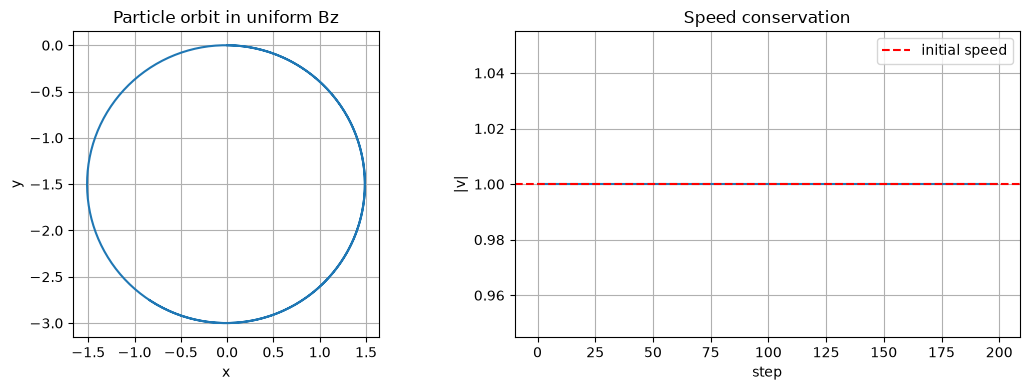

Boris 推进、能量保持、电场加速和周期边界均通过。


In [1]:
import os, sys
from pathlib import Path
module_dir = os.environ.get('BORIS_MODULE_DIR')
if module_dir is None:
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / 'build', parent / 'boris_cpp' / 'build'):
            if list(candidate.glob('boris_cpp*.so')): module_dir = str(candidate); break
        if module_dir: break
sys.path.insert(0, module_dir or '../build')
import math
import matplotlib.pyplot as plt
import boris_cpp as boris
%matplotlib inline

zero = boris.Vec3(0, 0, 0)
mesh = boris.UniformMesh(
    boris.Vec3(-10, -10, 0), boris.Vec3(20, 20, 0), (100, 100, 1),
    zero, boris.Vec3(0, 0, 1), boris.BoundaryCondition.PERIODIC
)
particle = boris.Particle(boris.Vec3(0, 0, 0), boris.Vec3(1, 0, 0), 1, 1)
positions = [(particle.position.x, particle.position.y)]
speeds = []
for _ in range(200):
    boris.push(particle, 0.05, mesh)
    positions.append((particle.position.x, particle.position.y))
    speeds.append(boris.norm(particle.velocity))

initial_speed = 1.0
assert max(abs(speed - initial_speed) for speed in speeds) < 1e-10

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot([p[0] for p in positions], [p[1] for p in positions])
axes[0].set(title='Particle orbit in uniform Bz', xlabel='x', ylabel='y', aspect='equal')
axes[0].grid(True)
axes[1].plot(speeds)
axes[1].axhline(initial_speed, color='red', linestyle='--', label='initial speed')
axes[1].set(title='Speed conservation', xlabel='step', ylabel='|v|')
axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

# 均匀电场加速：q/m * E * dt = 0.1。
electric_mesh = boris.UniformMesh(
    boris.Vec3(0, 0, 0), boris.Vec3(10, 10, 0), (10, 10, 1),
    boris.Vec3(2, 0, 0), zero
)
accelerated = boris.Particle(boris.Vec3(5, 5, 0), zero, 1, 2)
boris.push(accelerated, 0.1, electric_mesh)
assert abs(accelerated.velocity.x - 0.1) < 1e-12

# 周期边界：越过 x=10 后回到区域内部。
edge_mesh = boris.UniformMesh(
    boris.Vec3(0, 0, 0), boris.Vec3(10, 10, 0), (10, 10, 1),
    zero, zero, boris.BoundaryCondition.PERIODIC
)
edge_particle = boris.Particle(boris.Vec3(9.9, 5, 0), boris.Vec3(10, 0, 0), 1, 1)
boris.push(edge_particle, 0.1, edge_mesh)
assert edge_particle.alive and abs(edge_particle.position.x - 1.4) < 1e-12
print('Boris 推进、能量保持、电场加速和周期边界均通过。')